In [5]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import os
import seaborn as sns
import scipy.stats as stats

files = [x for x in os.listdir('data/') if 'human_results.csv' not in x]
print(files)

def rename_illusions(frame):
    frame = frame.rename(index={
    'argyleX': 'Argyle Cast',
    'argyle': 'Argyle Paint',
    'argylec': 'Argyle Control',
    'argylelX': 'Argyle Long Cast',
    'argylel': 'Argyle Long Paint',
    'argylelc': 'Argyle Long Control',
    'checkassim': 'Checkboard Paint',
    'koffkac': 'Koffka Control',
    'koffkasX': 'Koffka-Adelson Cast',
    'koffkas': 'Koffka-Adelson Paint',
    'koffkatX': 'Koffka Broken Cast',
    'koffkat': 'Koffka Broken Paint',
    'simconX': 'Simultaneous Contrast Cast',
    'simcon': 'Simultaneous Contrast Paint',
    'simconaX': 'Simultaneous Contrast Articulated Cast',
    'simcona': 'Simultaneous Contrast Articulated Paint',
    'snakeX': 'Snake Cast',
    'snake': 'Snake Paint',
    'snakec': 'Snake Control',
    'white': 'White Paint'
    })
    return frame


['match_av.csv', 'match_ac.csv', 'match_ap.csv', 'match_af.csv', 'match_hm.csv', 'match_mmg.csv', 'match_sa.csv', 'match_sl.csv', 'match_sk.csv', 'match_mkh.csv']


In [7]:
import matplotlib.cm as cm

colors = [
    "#FF6347",  # Reference color (red)
    "#003366",  # Dark shade of blue
    "#0A446D",
    "#145474",
    "#337589",
    "#478597",
    "#5BA6A5",
    "#66B6AC",
    "#7AD6BA",
    "#84E6C1",
    "#99FFCF",
]

first_color = '#FF6347'  # Bright red for the first bar
# Use a colormap for the remaining bars
colormap = cm.get_cmap('Blues', 20)  # Monochromatic color map 'Blues'
colors = [first_color] + [colormap(i) for i in range(15, 5, -1)] + ['#800080']


/var/folders/h1/q5d2smwx2xn8t7ggmjjhp_1c0000gn/T/ipykernel_94744/1021736824.py:19: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed two minor releases later. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap(obj)`` instead.
  colormap = cm.get_cmap('Blues', 20)  # Monochromatic color map 'Blues'


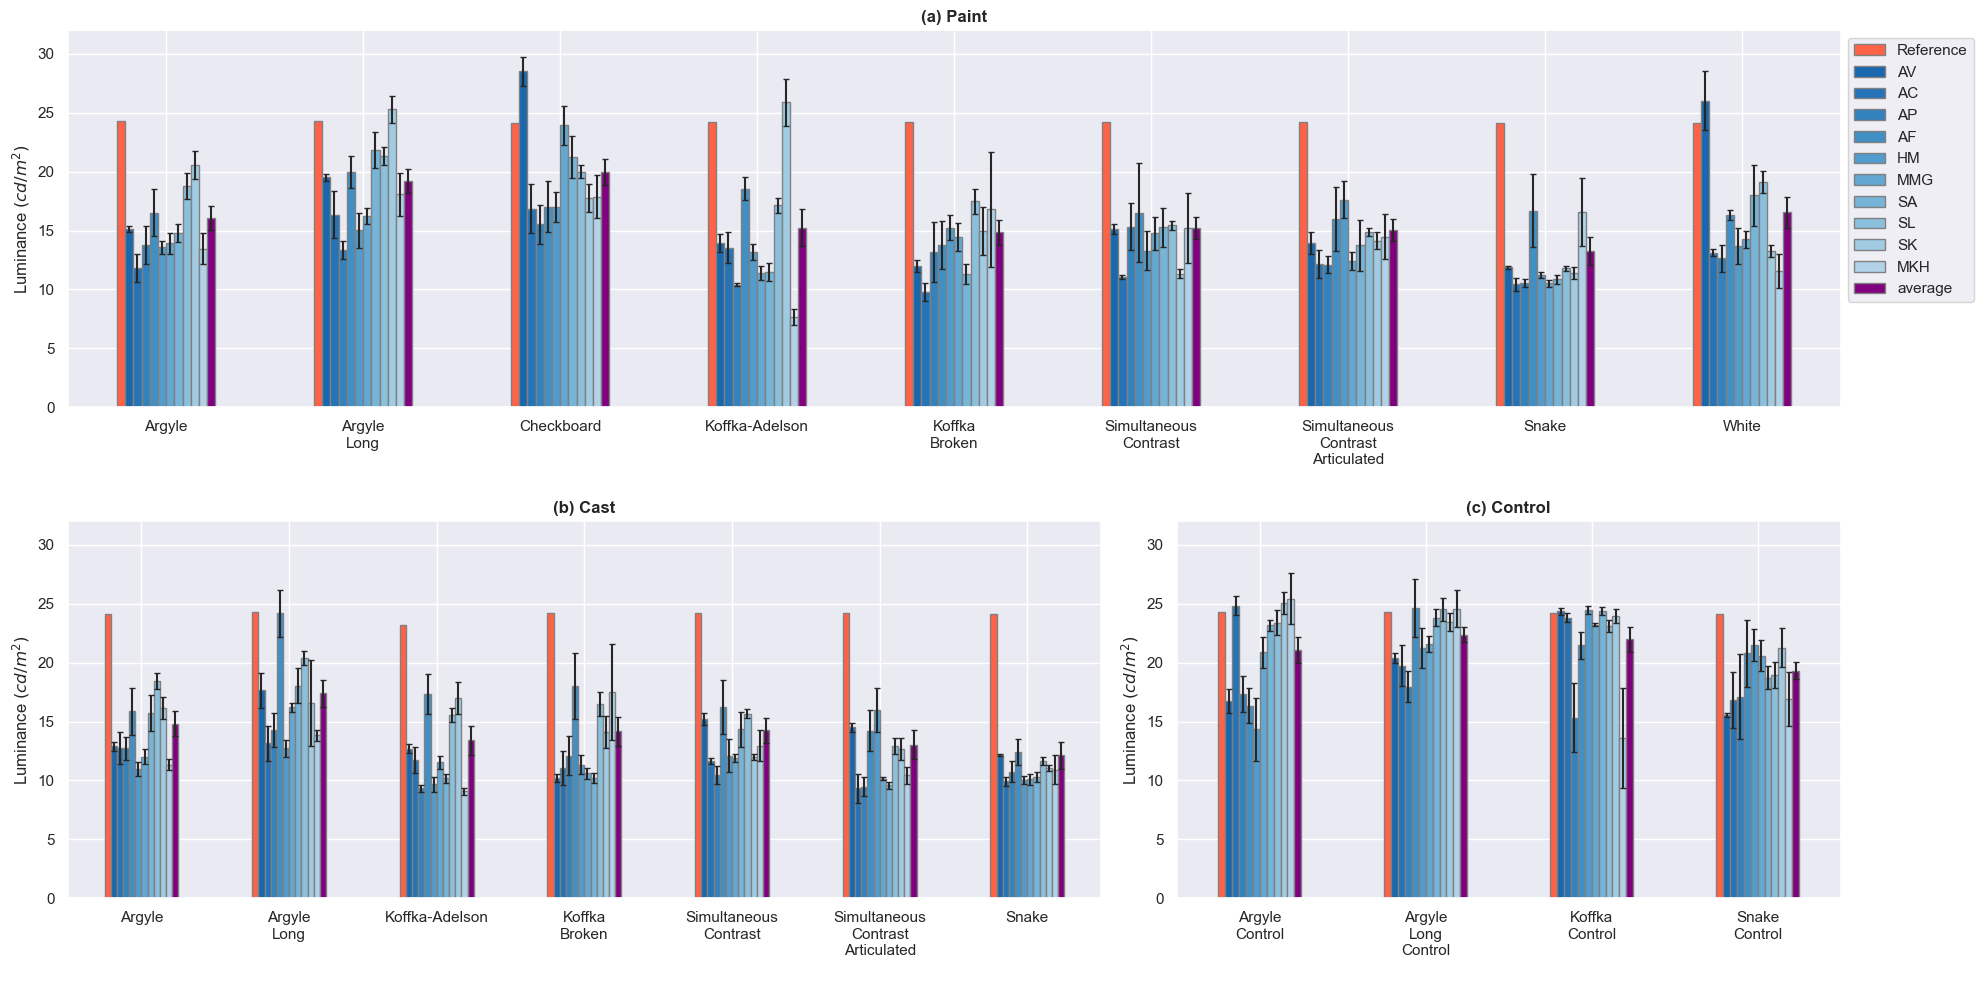

In [9]:
full_mean = pd.DataFrame()
full_se = pd.DataFrame()

titles = ['(a) Paint', '(b) Cast', '(c) Control']
conditions = ['Paint', 'Cast', '']
for i, name in enumerate(files):
    initials = name.split('.')[0].split('_')[1]

    df = pd.read_csv(f'data/{name}', comment='#')
    ref = df.groupby('name').mean()['reflum']

    df = df.drop(['trial', 'refgrey', 'matchgrey', 'rt', 'reflum'], axis=1)
    df = df.rename(columns={'matchlum': f'{initials.upper()}'})

    mean_df = df.groupby('name').mean()
    err_df = df.groupby('name').sem()

    if i > 0:
        full_mean = pd.concat([full_mean, mean_df], axis = 1)
        full_se = pd.concat([full_se, err_df], axis = 1)
    else:
        full_se = err_df
        full_mean = mean_df

        full_mean = pd.concat([full_mean, ref], axis = 1)
        full_se = pd.concat([full_se, ref], axis = 1)

sns.set_theme()

mods_df = full_mean.copy()
sig_testing = full_mean.copy()

full_mean = rename_illusions(full_mean)
full_mean['average'] = full_mean.T.mean()
full_se = rename_illusions(full_se).drop(columns='reflum')
full_se['average'] = full_mean.T.sem()

ref = full_mean['reflum']
full_mean.pop('reflum')
full_mean.insert(0, 'reflum', ref)
full_mean = full_mean.rename(columns={'reflum': 'Reference'})

df_paint = full_mean[full_mean.index.str.contains('Paint')]
df_shadow = full_mean[full_mean.index.str.contains('Cast')]
df_control = full_mean[full_mean.index.str.contains('Control')]

fig = plt.figure(figsize=(20, 10))
gs = fig.add_gridspec(2, 5)
ax1 = fig.add_subplot(gs[0, :])
ax2 = fig.add_subplot(gs[1, :3])
ax3 = fig.add_subplot(gs[1, 3:])

for i, (frame, cax) in enumerate(zip([df_paint, df_shadow, df_control], [ax1, ax2, ax3])):
    frame.plot.bar(ax = cax, yerr = full_se, legend = False, capsize=2, color=colors)
    cax.set_title(titles[i], weight='bold')
    for bar in cax.patches:
        bar.set_linewidth(1)
        bar.set_edgecolor('grey')

    cax.set_xticklabels([x.replace(' ', '\n').replace(conditions[i], '') for x in frame.index], rotation = 0)
    cax.set_ylabel('Luminance $(cd/m^2)$')
    cax.set_xlabel('')
    if i ==0:
        cax.legend(loc='upper left', bbox_to_anchor=(1, 1))

for pt in [ax1, ax2, ax3]:
    pt.set_ylim(0, 32)


full_mean = full_mean.drop(columns='Reference')
plt.tight_layout()
plt.show()


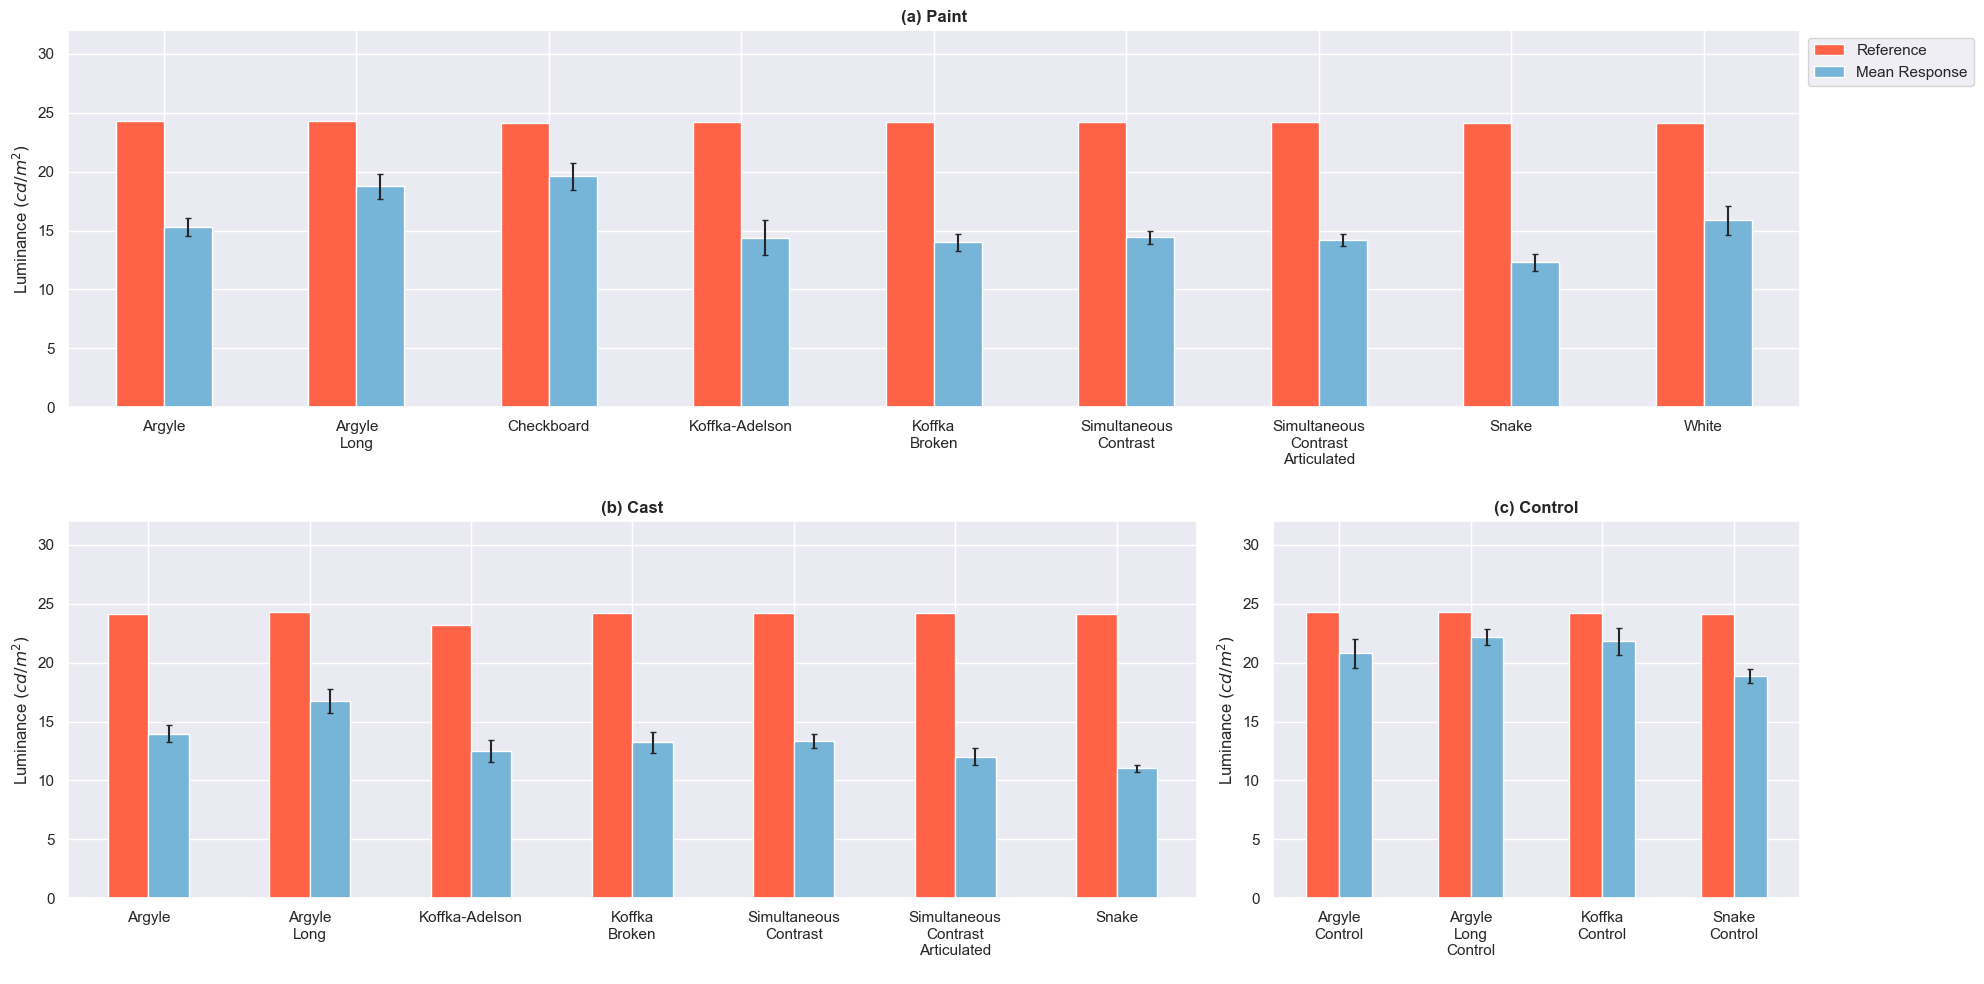

In [11]:
mean_df = pd.concat([ref, full_mean.T.mean()], axis = 1).rename(columns= {0: 'mean'})
mean_df = mean_df.rename(columns={'reflum': f'Reference', 'mean': 'Mean Response'})

y = pd.DataFrame()
y['Mean Response'] = full_mean.T.sem()

df_paint = mean_df[mean_df.index.str.contains('Paint')]
df_shadow = mean_df[mean_df.index.str.contains('Cast')]
df_control = mean_df[mean_df.index.str.contains('Control')]

fig = plt.figure(figsize=(20, 10))
gs = fig.add_gridspec(2, 3)
ax1 = fig.add_subplot(gs[0, :])
ax2 = fig.add_subplot(gs[1, :2])
ax3 = fig.add_subplot(gs[1, 2])

for i, (frame, cax) in enumerate(zip([df_paint, df_shadow, df_control], [ax1, ax2, ax3])):
    frame.plot.bar(ax = cax, yerr = y, legend = False, capsize=2, color=['#FF6347', colors[7]])
    cax.set_title(titles[i], weight='bold')
    cax.set_xticklabels([x.replace(' ', '\n').replace(conditions[i], '') for x in frame.index], rotation = 0)
    cax.set_ylabel('Luminance $(cd/m^2)$')
    cax.set_xlabel('')
    if i ==0:
        cax.legend(loc='upper left', bbox_to_anchor=(1, 1))

for pt in [ax1, ax2, ax3]:
    pt.set_ylim(0, 32)

plt.tight_layout()
plt.show()

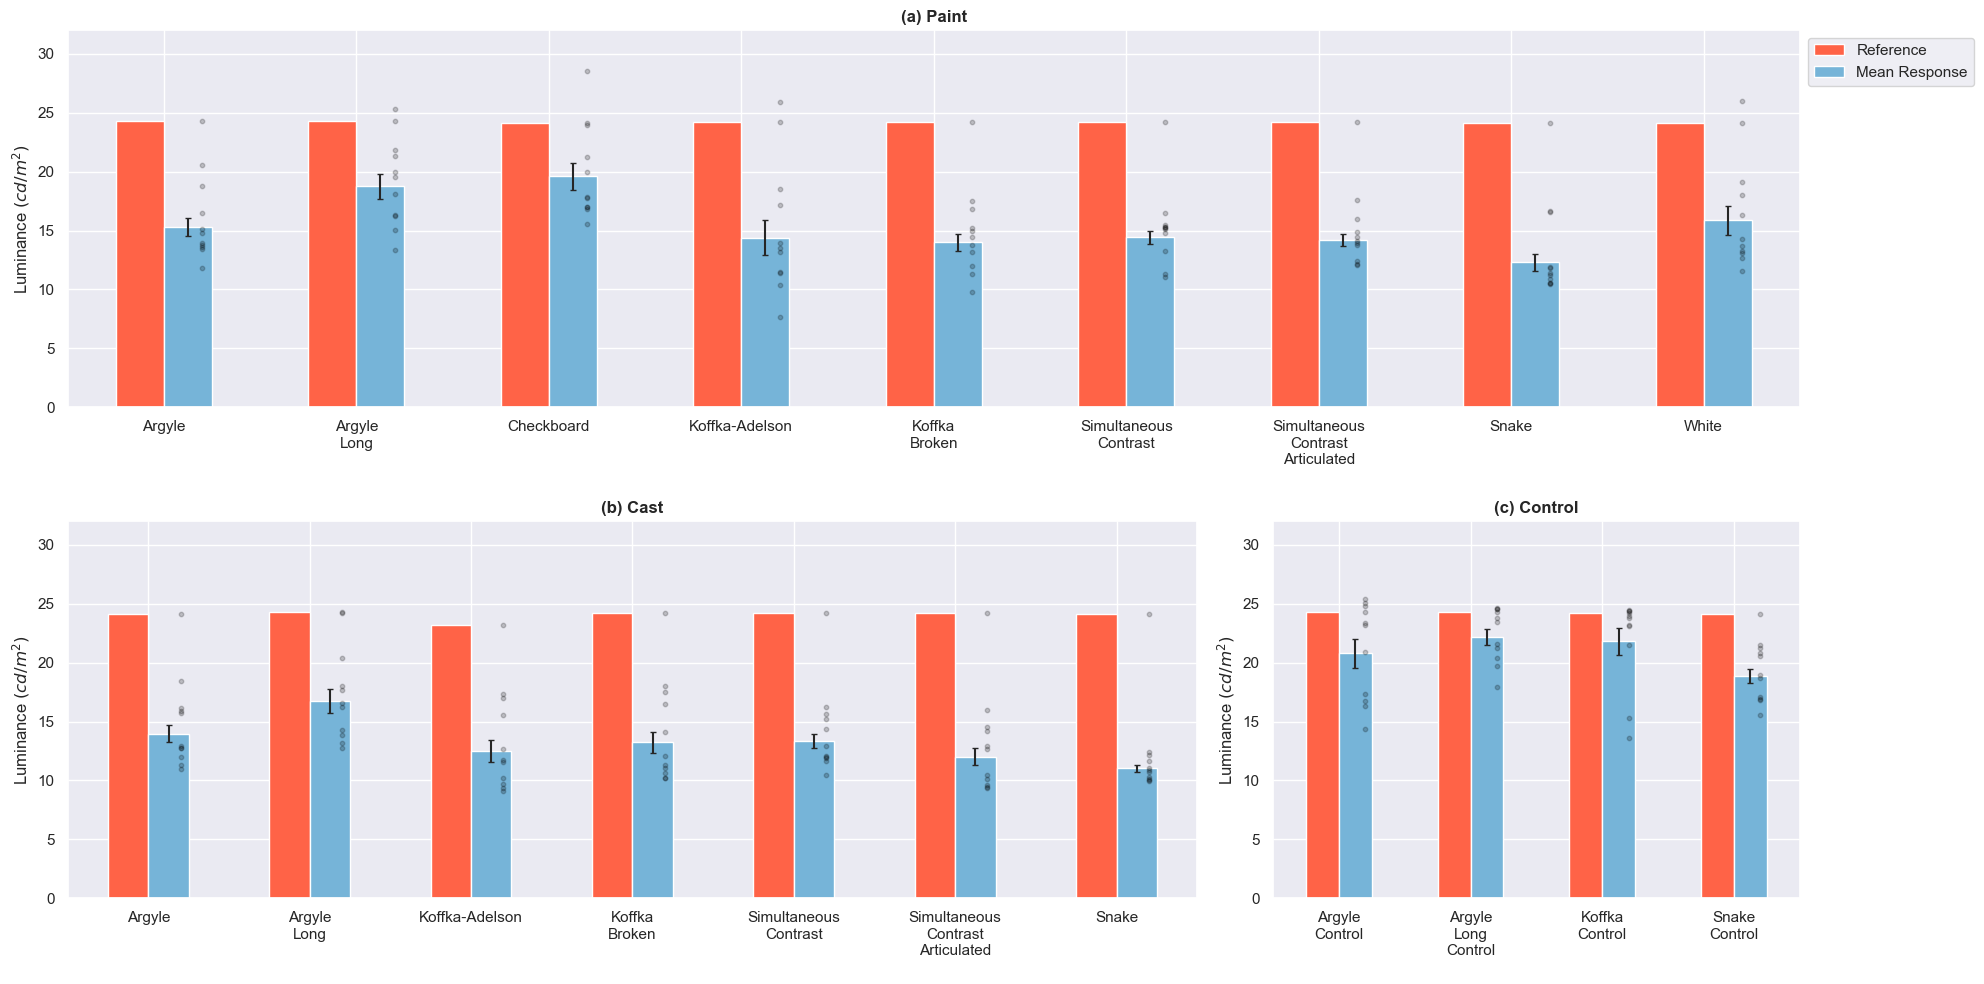

In [13]:
fig = plt.figure(figsize=(20, 10))
gs = fig.add_gridspec(2, 3)
ax1 = fig.add_subplot(gs[0, :])
ax2 = fig.add_subplot(gs[1, :2])
ax3 = fig.add_subplot(gs[1, 2])

mods_df = rename_illusions(mods_df)

# Add points from `full_mean` to respective frames
for i, (frame, cax, condition) in enumerate(zip([df_paint, df_shadow, df_control], [ax1, ax2, ax3], ['Paint', 'Cast', 'Control'])):
    frame.plot.bar(ax=cax, yerr=y, legend=False, capsize=2, color=['#FF6347', colors[7]])
    cax.set_title(titles[i], weight='bold')
    cax.set_xticklabels([x.replace(' ', '\n').replace(conditions[i], '') for x in frame.index], rotation=0)
    cax.set_ylabel('Luminance $(cd/m^2)$')
    cax.set_xlabel('')

    # Overlay individual points
    for j, idx in enumerate(frame.index):
        points = mods_df.T[idx]  # Extract points for the current index
        cax.scatter([j+0.2] * len(points), points, color='black', s=10, alpha=0.2, zorder=2)  # Plot points directly on the bar

    if i == 0:
        cax.legend(loc='upper left', bbox_to_anchor=(1, 1))

for pt in [ax1, ax2, ax3]:
    pt.set_ylim(0, 32)

plt.tight_layout()
plt.show()


## Significance Testing (One Tailed alpha 0.05, one tailed)

In [15]:
mod_dfs = pd.DataFrame()
for key in sig_testing.keys():
    if key == 'reflum':
        continue
    mod_dfs[key] = sig_testing['reflum'] - sig_testing[key]


In [17]:
def illusion_significance(model_df):
    mean_df = pd.DataFrame()
    mean_df['Difference']= model_df.mean(axis=1)
    mean_df['Error'] = model_df.sem(axis=1)
    mean_df['t-score'] = mean_df['Difference']/(mean_df['Error'])
    mean_df['Standard Deviation'] = mean_df['Error'] * np.sqrt(10)
    mean_df['(α=0.05, one tailed)'] = mean_df['t-score'] > 1.833
    mean_df['p-levels'] = [f'{1 - stats.t.cdf(abs(t), 9):.2e}' for t in mean_df['t-score']]

    mean_df = mean_df.sort_index(key = lambda x:x.str.split().str[-1])
    mean_df.index.name = 'Illusion Name'

    return mean_df

def illusion_comparisons(mod_dfs, tcrit=1.833):
    model = {}
    for mod_name, df in mod_dfs.items():

        name = mod_name.split('.')[0].split('_')[-1]
        
        c = {}
        for illusion, control, idx in zip(['argyle', 'argylel', 'koffkas', 'koffkat', 'snake'], ['argylec', 'argylelc', 'koffkac', 'koffkac', 'snakec'], ['Argyle', 'Argyle Long', 'Koffka-Adelson', 'Koffka Broken', 'Snake']):
            
            for condition in ['Paint', 'Cast']:
                if condition == 'Cast':
                    i = illusion + 'X'
                    c[f'{idx} {condition} vs Control'] = df.loc[i] - df.loc[control] 
                else:
                    i = illusion
                    c[f'{idx} {condition} vs Control'] = df.loc[i] - df.loc[control]

        model[name] = c

    df = pd.DataFrame.from_dict(model)
    ttest_df = pd.DataFrame({
        'Difference': df.T.mean(),
        'Error': df.T.sem(),
        '(α=0.05, one tailed)': (df.T.mean()/df.T.sem()) > tcrit,
    })
    ttest_df['t-score'] = df.T.mean()/df.T.sem()
    ttest_df['p-levels'] = [f'{1 - stats.t.cdf(abs(t), 9):.2e}' for t in ttest_df['t-score']]


    return ttest_df

m_df = illusion_significance(rename_illusions(mod_dfs))
ttest_df = illusion_comparisons(mod_dfs)


In [19]:
f = pd.concat([m_df[['t-score', 'p-levels', '(α=0.05, one tailed)']], ttest_df[['t-score', 'p-levels', '(α=0.05, one tailed)']]])

f

,t-score,p-levels,"(α=0.05, one tailed)"
Koffka-Adelson Cast,10.807851,9.34e-07,True
Argyle Cast,13.155066,1.75e-07,True
Snake Cast,46.805714,2.32e-12,True
Argyle Long Cast,6.703228,4.41e-05,True
Simultaneous Contrast Articulated Cast,15.963647,3.28e-08,True
Koffka Broken Cast,11.260757,6.60e-07,True
Simultaneous Contrast Cast,17.568724,1.42e-08,True
Argyle Control,2.698785,1.22e-02,True
Argyle Long Control,2.884058,9.03e-03,True
Koffka Control,1.957359,4.10e-02,True
